In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

In [16]:
df = pd.read_parquet("../data/cleaned_data.parquet")
df.head(3)

,order_id,order_date,order_hour,day_of_week,is_weekend,is_festival,weather,pickup_zone,dropoff_zone,vehicle_type,...,preparation_time_min,road_distance_km,delivery_distance_category,traffic_level,number_of_signals,average_speed_kmph,delivery_priority,time_taken_min,month,traffic_lvl_code
0,ORD000001,2025-10-28,8,tuesday,0,0,clear,cbd,commercial,scooter,...,23,30.55,long,moderate,15,28.7,normal,91,October,2
1,ORD000002,2025-09-26,12,friday,0,0,rain,cbd,cbd,scooter,...,11,2.25,short,moderate,17,23.3,normal,21,September,2
2,ORD000003,2025-01-26,18,sunday,1,0,clear,residential,residential,scooter,...,31,10.15,long,moderate,8,28.9,normal,52,January,2


In [17]:
months = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

In [18]:
# How many orders do we handle each month, and is volume growing or flat?
monthly_orders = df.groupby("month").agg(
    volume = ("order_id","count")
).reset_index()
monthly_orders["month"] = pd.Categorical(monthly_orders["month"], categories=months, ordered=True)
monthly_orders = monthly_orders.sort_values(by="month")
monthly_orders


,month,volume
4,January,4172
3,February,3872
7,March,4335
0,April,4135
8,May,4189
6,June,4204
5,July,4175
1,August,4270
11,September,4169
10,October,4199


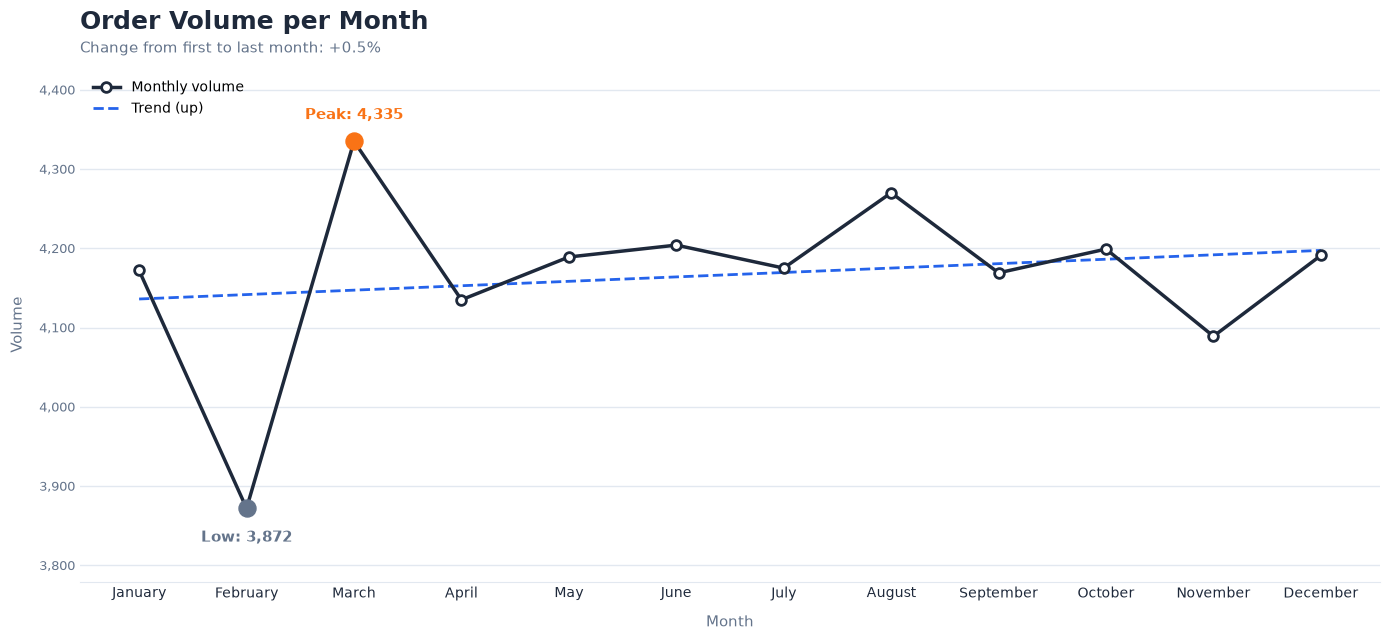

In [19]:

from matplotlib.ticker import FuncFormatter

# --- Palette ---
PEAK   = "#F97316"
LINE   = "#1E293B"
TREND  = "#2563EB"
TEXT   = "#1E293B"
MUTED  = "#64748B"
GRID   = "#E2E8F0"

months = monthly_orders["month"].reset_index(drop=True)
volume = monthly_orders["volume"].reset_index(drop=True)
x = np.arange(len(volume))

# Trend line (linear fit)
slope, intercept = np.polyfit(x, volume, 1)
trend = slope * x + intercept

i_max = volume.idxmax()
i_min = volume.idxmin()

fig, ax = plt.subplots(figsize=(14, 6.5))
fig.patch.set_facecolor("white")

# Actual values
ax.plot(x, volume, color=LINE, linewidth=2.5, marker="o", markersize=7,
        markerfacecolor="white", markeredgewidth=2, zorder=3, label="Monthly volume")

# Trend line
ax.plot(x, trend, color=TREND, linewidth=2, linestyle="--", zorder=2,
        label=f"Trend ({'up' if slope > 0 else 'down'})")

# Peak and low
ax.scatter(i_max, volume[i_max], s=150, color=PEAK, zorder=4)
ax.scatter(i_min, volume[i_min], s=150, color=MUTED, zorder=4)
ax.annotate(f"Peak: {volume[i_max]:,.0f}", (i_max, volume[i_max]),
            xytext=(0, 16), textcoords="offset points", ha="center",
            fontsize=11, fontweight="bold", color=PEAK)
ax.annotate(f"Low: {volume[i_min]:,.0f}", (i_min, volume[i_min]),
            xytext=(0, -24), textcoords="offset points", ha="center",
            fontsize=11, fontweight="bold", color=MUTED)

# Zoom into the real range (NOT starting from 0)
pad = (volume.max() - volume.min()) * 0.2
ax.set_ylim(volume.min() - pad, volume.max() + pad)

# Overall change from first to last month
change = (volume.iloc[-1] - volume.iloc[0]) / volume.iloc[0] * 100
ax.set_title("Order Volume per Month", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03, f"Change from first to last month: {change:+.1f}%",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xticks(x)
ax.set_xticklabels(months, fontsize=10, color=TEXT)
ax.set_xlabel("Month", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Volume", fontsize=11, color=MUTED, labelpad=10)
ax.tick_params(axis="both", length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(frameon=False, loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

In [20]:
# What share of orders are delivered late
late_deliveries = df[df["time_taken_min"] >= 100]
late_deliveries

,order_id,order_date,order_hour,day_of_week,is_weekend,is_festival,weather,pickup_zone,dropoff_zone,vehicle_type,...,preparation_time_min,road_distance_km,delivery_distance_category,traffic_level,number_of_signals,average_speed_kmph,delivery_priority,time_taken_min,month,traffic_lvl_code
5,ORD000006,2025-01-22,18,wednesday,0,0,cloudy,cbd,suburban,electric scooter,...,16,34.05,long,moderate,16,24.2,normal,105,January,2
6,ORD000007,2025-08-19,12,tuesday,0,0,rain,commercial,commercial,bicycle,...,13,38.80,long,low,10,13.4,normal,180,August,1
8,ORD000009,2025-01-23,8,thursday,0,1,cloudy,cbd,residential,bike,...,33,33.04,long,high,17,29.2,normal,110,January,3
13,ORD000014,2025-06-24,12,tuesday,0,0,clear,industrial,cbd,bicycle,...,31,34.79,long,low,8,16.2,normal,162,June,1
23,ORD000024,2025-07-24,17,thursday,0,0,storm,residential,residential,scooter,...,31,41.46,long,low,9,24.6,normal,145,July,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49987,ORD049988,2025-02-19,10,wednesday,0,0,storm,residential,commercial,bike,...,36,27.96,long,moderate,10,24.0,normal,118,February,2
49990,ORD049991,2025-12-24,20,wednesday,0,0,fog,cbd,industrial,electric scooter,...,25,42.09,long,moderate,17,22.6,normal,137,December,2
49993,ORD049994,2025-09-28,10,sunday,1,0,rain,industrial,residential,electric scooter,...,32,34.29,long,high,4,16.6,normal,164,September,3
49994,ORD049995,2025-12-27,7,saturday,1,0,cloudy,residential,residential,bike,...,41,40.37,long,low,6,42.9,normal,105,December,1


In [21]:
# Is our average delivery time improving or getting worse over the year
avg_delivery_time_mt = df.groupby("month").agg(
    avg_delivery_time = ("time_taken_min","median")
).reset_index().round()
avg_delivery_time_mt["month"] = pd.Categorical(avg_delivery_time_mt["month"], categories=months, ordered=True)
avg_delivery_time_mt = avg_delivery_time_mt.sort_values(by="month")
avg_delivery_time_mt

,month,avg_delivery_time
4,January,78.0
3,February,78.0
7,March,79.0
0,April,77.0
8,May,78.0
6,June,78.0
5,July,77.0
1,August,78.0
11,September,77.0
10,October,77.0


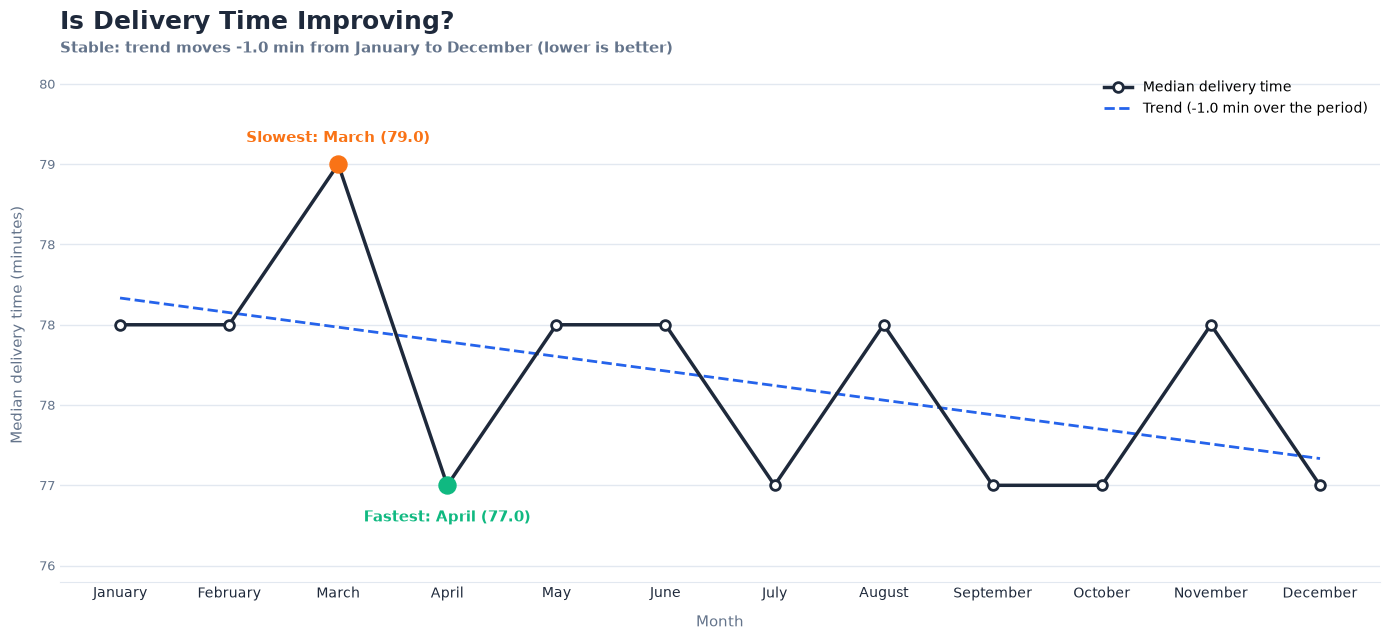

In [22]:
# --- Palette (same as the other charts) ---
PEAK   = "#F97316"   # slowest month
GOOD   = "#10B981"   # fastest month
LINE   = "#1E293B"
TREND  = "#2563EB"
TEXT   = "#1E293B"
MUTED  = "#64748B"
GRID   = "#E2E8F0"

data = avg_delivery_time_mt.sort_values("month").reset_index(drop=True)
labels = data["month"].astype(str)
vals   = data["avg_delivery_time"].astype(float)
x = np.arange(len(vals))

# Trend (linear fit) and verdict
slope, intercept = np.polyfit(x, vals, 1)
trend = slope * x + intercept
trend_change = slope * (len(vals) - 1)          # minutes gained/lost over the year
if abs(trend_change) < 0.02 * vals.mean():
    verdict, v_color = "Stable", MUTED
elif trend_change < 0:
    verdict, v_color = "Improving", GOOD
else:
    verdict, v_color = "Getting worse", PEAK

i_worst, i_best = vals.idxmax(), vals.idxmin()

fig, ax = plt.subplots(figsize=(14, 6.5))
fig.patch.set_facecolor("white")

# Actual values
ax.plot(x, vals, color=LINE, linewidth=2.5, marker="o", markersize=7,
        markerfacecolor="white", markeredgewidth=2, zorder=3,
        label="Median delivery time")

# Trend line
ax.plot(x, trend, color=TREND, linewidth=2, linestyle="--", zorder=2,
        label=f"Trend ({trend_change:+.1f} min over the period)")

# Slowest and fastest months
ax.scatter(i_worst, vals[i_worst], s=150, color=PEAK, zorder=4)
ax.scatter(i_best,  vals[i_best],  s=150, color=GOOD, zorder=4)
ax.annotate(f"Slowest: {labels[i_worst]} ({vals[i_worst]:.1f})", (i_worst, vals[i_worst]),
            xytext=(0, 16), textcoords="offset points", ha="center",
            fontsize=11, fontweight="bold", color=PEAK)
ax.annotate(f"Fastest: {labels[i_best]} ({vals[i_best]:.1f})", (i_best, vals[i_best]),
            xytext=(0, -26), textcoords="offset points", ha="center",
            fontsize=11, fontweight="bold", color=GOOD)

# Zoom into the real range
pad = (vals.max() - vals.min()) * 0.3 or 1
ax.set_ylim(vals.min() - pad, vals.max() + pad)

# Titles
ax.set_title("Is Delivery Time Improving?", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03, f"{verdict}: trend moves {trend_change:+.1f} min from "
        f"{labels.iloc[0]} to {labels.iloc[-1]} (lower is better)",
        transform=ax.transAxes, fontsize=11, color=v_color, fontweight="bold")

# Axes
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10, color=TEXT)
ax.set_xlabel("Month", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Median delivery time (minutes)", fontsize=11, color=MUTED, labelpad=10)
ax.tick_params(axis="both", length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(frameon=False, loc="upper right", fontsize=10)

plt.tight_layout()
plt.show()

In [23]:
# How consistent is our service? How wide is the gap between our fastest
#      and slowest deliveries?

service_consistency = df.groupby(["delivery_distance_category", "vehicle_type"]).agg(
    avg_time = ("time_taken_min","median"),
    min_time = ("time_taken_min","min"),
    max_time = ("time_taken_min","max")
).reset_index()
service_consistency

,delivery_distance_category,vehicle_type,avg_time,min_time,max_time
0,long,bicycle,139.0,36,180
1,long,bike,71.0,13,180
2,long,electric scooter,88.0,20,180
3,long,scooter,81.0,20,180
4,medium,bicycle,51.0,20,92
5,medium,bike,37.0,12,77
6,medium,electric scooter,40.0,14,77
7,medium,scooter,40.0,15,66
8,short,bicycle,42.0,12,59
9,short,bike,33.0,10,58


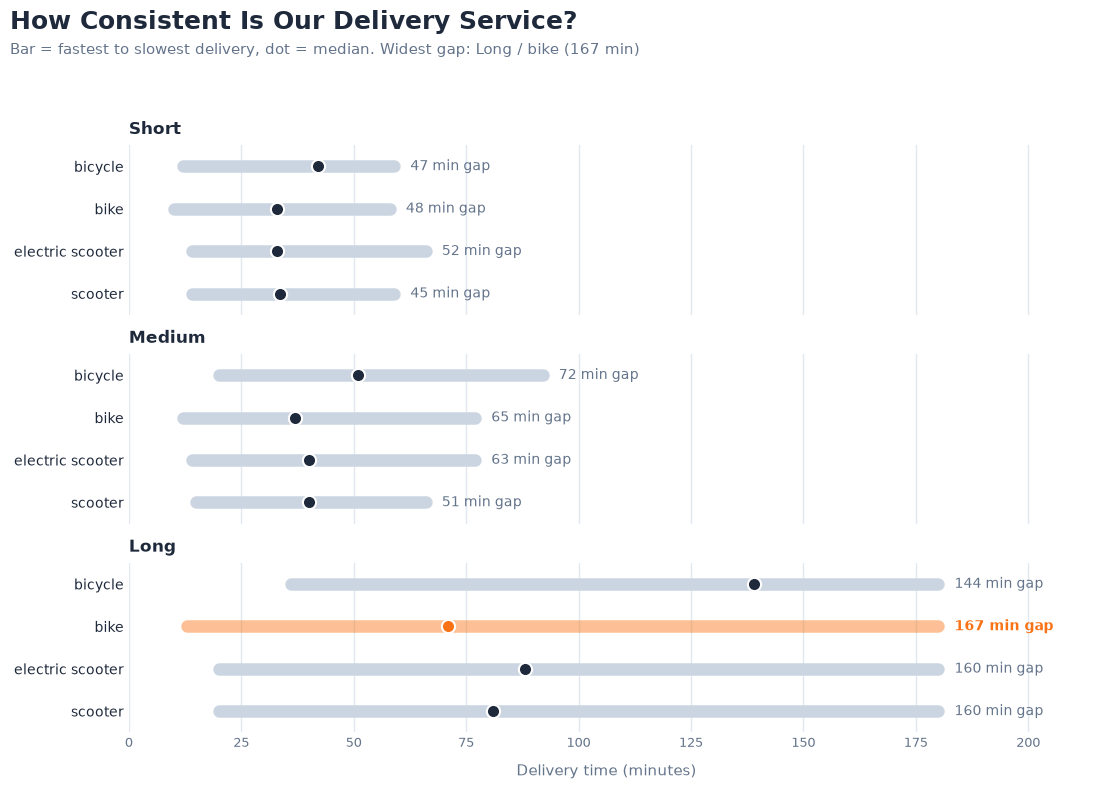

In [26]:
# --- Palette (same as the other charts) ---
BASE   = "#CBD5E1"
PEAK   = "#F97316"
DOT    = "#1E293B"
TEXT   = "#1E293B"
MUTED  = "#64748B"
GRID   = "#E2E8F0"

data = service_consistency.copy()
data["spread"] = data["max_time"] - data["min_time"]

# Natural order of distance categories (adjust names to match your data)
order = ["Short", "Medium", "Long"]
data["delivery_distance_category"] = data["delivery_distance_category"].astype(str)
if set(data["delivery_distance_category"].str.title()) == set(order):
    data["delivery_distance_category"] = data["delivery_distance_category"].str.title()
    cats = order
else:
    cats = list(data["delivery_distance_category"].unique())

vehicles = sorted(data["vehicle_type"].unique())

# Widest gap overall
w = data.loc[data["spread"].idxmax()]
w_key = (w["delivery_distance_category"], w["vehicle_type"])

fig, axes = plt.subplots(len(cats), 1, sharex=True,
                         figsize=(11, 1.5 * len(cats) * max(1, len(vehicles) / 3) + 2))
axes = np.atleast_1d(axes)
fig.patch.set_facecolor("white")

x_max = data["max_time"].max()

for ax, cat in zip(axes, cats):
    sub = data[data["delivery_distance_category"] == cat].set_index("vehicle_type")

    for j, veh in enumerate(vehicles):
        if veh not in sub.index:
            continue
        r = sub.loc[veh]
        hot = (cat, veh) == w_key
        c = PEAK if hot else DOT

        # Range bar
        ax.plot([r["min_time"], r["max_time"]], [j, j], color=PEAK if hot else BASE,
                linewidth=9, solid_capstyle="round", alpha=0.45 if hot else 1, zorder=2)
        # Median dot
        ax.scatter(r["avg_time"], j, s=90, color=c, edgecolor="white",
                   linewidth=1.5, zorder=4)
        # One label: gap at the end of the bar
        ax.text(r["max_time"] + x_max * 0.02, j, f"{r['spread']:.0f} min gap",
                va="center", fontsize=10, color=PEAK if hot else MUTED,
                fontweight="bold" if hot else "normal")

    ax.set_yticks(range(len(vehicles)))
    ax.set_yticklabels(vehicles, fontsize=10, color=TEXT)
    ax.set_ylim(len(vehicles) - 0.5, -0.5)
    ax.set_title(cat, loc="left", fontsize=12, fontweight="bold", color=TEXT, pad=8)
    ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(False)

axes[-1].set_xlim(0, x_max * 1.18)
axes[-1].set_xlabel("Delivery time (minutes)", fontsize=11, color=MUTED, labelpad=10)
axes[-1].tick_params(axis="x", labelsize=9, colors=MUTED)
axes[-1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# Title + subtitle
fig.suptitle("How Consistent Is Our Delivery Service?", x=0.01, ha="left",
             fontsize=18, fontweight="bold", color=TEXT)
fig.text(0.01, 0.925,
         f"Bar = fastest to slowest delivery, dot = median. "
         f"Widest gap: {w_key[0]} / {w_key[1]} ({w['spread']:.0f} min)",
         fontsize=11, color=MUTED)

plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

In [25]:
longdistance = df[df["delivery_distance_category"] == "short"]
longdistance

,order_id,order_date,order_hour,day_of_week,is_weekend,is_festival,weather,pickup_zone,dropoff_zone,vehicle_type,...,preparation_time_min,road_distance_km,delivery_distance_category,traffic_level,number_of_signals,average_speed_kmph,delivery_priority,time_taken_min,month,traffic_lvl_code
1,ORD000002,2025-09-26,12,friday,0,0,rain,cbd,cbd,scooter,...,11,2.25,short,moderate,17,23.3,normal,21,September,2
11,ORD000012,2025-01-12,12,sunday,1,0,cloudy,industrial,residential,bike,...,32,1.20,short,low,4,44.5,normal,41,January,1
32,ORD000033,2025-09-04,18,thursday,0,0,fog,industrial,industrial,bike,...,29,2.06,short,low,7,39.0,normal,36,September,1
127,ORD000128,2025-03-10,0,monday,0,0,clear,commercial,residential,bicycle,...,12,0.99,short,low,13,16.5,normal,20,March,1
179,ORD000180,2025-02-04,11,tuesday,0,0,clear,residential,cbd,bike,...,26,2.15,short,low,9,42.5,normal,28,February,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49383,ORD049384,2025-08-30,19,saturday,1,0,cloudy,cbd,residential,electric scooter,...,9,2.70,short,high,14,19.2,normal,20,August,3
49457,ORD049458,2025-08-14,5,thursday,0,0,rain,commercial,cbd,bike,...,12,2.16,short,low,11,36.6,normal,22,August,1
49472,ORD049473,2025-03-12,18,wednesday,0,0,rain,residential,residential,bike,...,13,1.12,short,moderate,9,29.8,normal,23,March,2
49719,ORD049720,2025-10-09,17,thursday,0,0,rain,commercial,residential,bike,...,10,2.55,short,low,11,36.0,priority,25,October,1
